# Course 10: Deep Learning on Curved Spaces
## Session 6: Computing in hyperbolic space: the Poincaré and Lorentz models

**Goal:** implement Möbius addition, distances, exponential and logarithm maps in the Poincaré ball with curvature −c and in the Lorentz model, convert between them, and measure where float32 and float64 break.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. By hand: Möbius addition in one and two dimensions
The **Poincaré ball with curvature $-c$** ($c > 0$) is the ball $\{x : c\|x\|^2 < 1\}$ of radius $1/\sqrt c$. Session 4 used $c = 1$. Points are added with **Möbius addition** (Ungar 2008; Ganea et al. 2018):
$$x \oplus_c y = \frac{(1 + 2c\langle x, y\rangle + c\|y\|^2)\,x + (1 - c\|x\|^2)\,y}{1 + 2c\langle x, y\rangle + c^2\|x\|^2\|y\|^2}.$$
By hand, with $c = 1$:

* in one dimension the formula becomes $x \oplus y = \frac{x + y}{1 + xy}$ (the rule for adding velocities in special relativity, with the speed of light 1). What is $0.5 \oplus 0.5$?
* in two dimensions, take $x = (0.5, 0)$ and $y = (0, 0.5)$. Then $\langle x, y\rangle = 0$, $\|x\|^2 = \|y\|^2 = 0.25$, and $x \oplus y = (1.25\,x + 0.75\,y)/1.0625 = (0.5882, 0.3529)$. Now compute $y \oplus x$.

In [1]:
import time
import numpy as np
import torch
import matplotlib.pyplot as plt

t_start = time.time()
torch.set_num_threads(1)
rng = np.random.default_rng(0)

def mobius_add(x, y, c=1.0):
    xy = np.sum(x * y, axis=-1, keepdims=True); x2 = np.sum(x * x, axis=-1, keepdims=True); y2 = np.sum(y * y, axis=-1, keepdims=True)
    return ((1 + 2 * c * xy + c * y2) * x + (1 - c * x2) * y) / (1 + 2 * c * xy + c ** 2 * x2 * y2)

x, y = np.array([0.5, 0.0]), np.array([0.0, 0.5])
print(f"1-D: 0.5 (+) 0.5 = {mobius_add(np.array([0.5]), np.array([0.5]))[0]:.4f}")
print(f"2-D: x (+) y = {mobius_add(x, y).round(4)}, y (+) x = {mobius_add(y, x).round(4)}; "
      f"norms {np.linalg.norm(mobius_add(x, y)):.4f} and {np.linalg.norm(mobius_add(y, x)):.4f}")
print(f"(-x) (+) x = {mobius_add(-x, x) + 0.0}, and 0 (+) y = y: {mobius_add(np.zeros(2), y)}")

1-D: 0.5 (+) 0.5 = 0.8000
2-D: x (+) y = [0.5882 0.3529], y (+) x = [0.3529 0.5882]; norms 0.6860 and 0.6860
(-x) (+) x = [0. 0.], and 0 (+) y = y: [0.  0.5]


### 2. Distance, exponential and logarithm maps for curvature $-c$
With the **conformal factor** $\lambda_x^c = \frac{2}{1 - c\|x\|^2}$ (the Riemannian length of a tangent vector $v$ at $x$ is $\lambda_x^c\|v\|$), Ganea et al. 2018 give:
$$d_c(x, y) = \tfrac{2}{\sqrt c}\operatorname{artanh}\big(\sqrt c\,\|(-x)\oplus_c y\|\big) = \tfrac{1}{\sqrt c}\operatorname{arcosh}\Big(1 + \tfrac{2c\|x - y\|^2}{(1 - c\|x\|^2)(1 - c\|y\|^2)}\Big),$$
$$\exp_x^c(v) = x \oplus_c \Big(\tanh\big(\tfrac{\sqrt c\,\lambda_x^c\|v\|}{2}\big)\frac{v}{\sqrt c\,\|v\|}\Big), \qquad \log_x^c(y) = \frac{2}{\sqrt c\,\lambda_x^c}\operatorname{artanh}\big(\sqrt c\,\|w\|\big)\frac{w}{\|w\|},\ \ w = (-x)\oplus_c y.$$
At the origin $\lambda_0^c = 2$, so $\exp_0^c(v) = \tanh(\sqrt c\|v\|)\frac{v}{\sqrt c\|v\|}$ and $d_c(0, x) = \frac{2}{\sqrt c}\operatorname{artanh}(\sqrt c\|x\|)$. By hand: $d_1(0, (0.5, 0)) = 2\operatorname{artanh}(0.5) = \ln 3$, and $d_2(0, (0.5, 0)) = \sqrt2\operatorname{artanh}(0.5\sqrt2) \approx 1.2465$. We check, for $c$ = 0.5, 1 and 2 on 500 random pairs: the two distance formulas agree, exp and log invert each other, and $d(x, y) = \lambda_x\|\log_x y\|$. Finally, as $c \to 0$ the ball becomes flat and $d_c(x, y) \to 2\|x - y\|$ (the factor 2 is $\lambda_0$).

In [2]:
def lam(x, c=1.0):
    return 2 / (1 - c * np.sum(x * x, axis=-1, keepdims=True))

def dist(x, y, c=1.0):
    return 2 / np.sqrt(c) * np.arctanh(np.sqrt(c) * np.linalg.norm(mobius_add(-x, y, c), axis=-1))

def dist_arcosh(x, y, c=1.0):
    num = 2 * c * np.sum((x - y) ** 2, axis=-1)
    return np.arccosh(1 + num / ((1 - c * np.sum(x * x, axis=-1)) * (1 - c * np.sum(y * y, axis=-1)))) / np.sqrt(c)

def expmap(x, v, c=1.0):
    nv = np.maximum(np.linalg.norm(v, axis=-1, keepdims=True), 1e-15)      # avoid 0/0 when v = 0
    return mobius_add(x, np.tanh(np.sqrt(c) * lam(x, c) * nv / 2) * v / (np.sqrt(c) * nv), c)

def logmap(x, y, c=1.0):
    w = mobius_add(-x, y, c); nw = np.maximum(np.linalg.norm(w, axis=-1, keepdims=True), 1e-15)
    return 2 / (np.sqrt(c) * lam(x, c)) * np.arctanh(np.sqrt(c) * nw) * w / nw

def random_ball(m, c, rmax=0.9):                 # random points with sqrt(c) |x| < rmax
    u = rng.normal(size=(m, 2)); u /= np.linalg.norm(u, axis=1, keepdims=True)
    return u * rng.uniform(0, rmax, (m, 1)) / np.sqrt(c)

o, p = np.zeros(2), np.array([0.5, 0.0])
print(f"d_1(0, (0.5, 0)) = {dist(o, p):.10f} (ln 3 = {np.log(3):.10f}); d_2(0, (0.5, 0)) = {dist(o, p, 2.0):.4f}")
for c in [0.5, 1.0, 2.0]:
    X, Y = random_ball(500, c), random_ball(500, c)
    V = logmap(X, Y, c)
    print(f"c = {c}: two distance formulas differ by {np.abs(dist(X, Y, c) - dist_arcosh(X, Y, c)).max():.1e}; exp_x(log_x y) = y to {np.abs(expmap(X, V, c) - Y).max():.1e}; "
          f"log_x(exp_x v) = v to {np.abs(logmap(X, expmap(X, V, c), c) - V).max():.1e}; lambda_x |log_x y| = d(x, y) to {np.abs(lam(X, c)[:, 0] * np.linalg.norm(V, axis=1) - dist(X, Y, c)).max():.1e}")
X, Y = random_ball(5, 1.0), random_ball(5, 1.0)
for c in [1e-2, 1e-4, 1e-6]:
    print(f"c = {c:.0e}: largest |d_c(x, y) - 2 |x - y|| = {np.abs(dist(X, Y, c) - 2 * np.linalg.norm(X - Y, axis=1)).max():.1e}")

d_1(0, (0.5, 0)) = 1.0986122887 (ln 3 = 1.0986122887); d_2(0, (0.5, 0)) = 1.2465
c = 0.5: two distance formulas differ by 1.6e-14; exp_x(log_x y) = y to 1.6e-14; log_x(exp_x v) = v to 5.8e-15; lambda_x |log_x y| = d(x, y) to 1.8e-15
c = 1.0: two distance formulas differ by 6.2e-15; exp_x(log_x y) = y to 6.6e-15; log_x(exp_x v) = v to 4.7e-15; lambda_x |log_x y| = d(x, y) to 8.9e-16
c = 2.0: two distance formulas differ by 6.7e-15; exp_x(log_x y) = y to 3.7e-15; log_x(exp_x v) = v to 2.6e-15; lambda_x |log_x y| = d(x, y) to 8.9e-16
c = 1e-02: largest |d_c(x, y) - 2 |x - y|| = 6.5e-03
c = 1e-04: largest |d_c(x, y) - 2 |x - y|| = 6.5e-05
c = 1e-06: largest |d_c(x, y) - 2 |x - y|| = 6.5e-07


### 3. Gyrovector laws: what survives and what breaks
Möbius addition is not ordinary addition. Ungar's **gyrovector space** laws say what survives (Ungar 2008):

* left cancellation: $(-x) \oplus (x \oplus y) = y$;
* commutativity fails, but only by a rotation: $x \oplus y$ and $y \oplus x$ have the same norm;
* associativity fails, and is repaired by the **gyration** $\operatorname{gyr}[a, b]\,z = -(a\oplus b) \oplus \big(a \oplus (b \oplus z)\big)$, a rotation: $a \oplus (b \oplus z) = (a \oplus b) \oplus \operatorname{gyr}[a, b]\,z$;
* left translations $y \mapsto a \oplus y$ keep distances (they are isometries, like the Möbius maps of session 4); right translations $y \mapsto y \oplus a$ do not.

**Möbius scalar multiplication** $r \otimes_c x = \frac{1}{\sqrt c}\tanh\big(r\operatorname{artanh}(\sqrt c\|x\|)\big)\frac{x}{\|x\|}$ moves along the geodesic through 0 and $x$, multiplying the distance from 0 by $r$; for example $2 \otimes x = x \oplus x$. In one dimension everything commutes and the gyrations are trivial.

In [3]:
def scalar_mul(r, x, c=1.0):
    nx = np.maximum(np.linalg.norm(x, axis=-1, keepdims=True), 1e-15)
    return np.tanh(r * np.arctanh(np.sqrt(c) * nx)) * x / (np.sqrt(c) * nx)

c = 1.0
A_, B_, Z_ = random_ball(500, c), random_ball(500, c), random_ball(500, c)
gyr = mobius_add(-mobius_add(A_, B_), mobius_add(A_, mobius_add(B_, Z_)))
a0 = random_ball(1, c)[0]
print(f"left cancellation (-a) (+) (a (+) b) = b: largest error {np.abs(mobius_add(-A_, mobius_add(A_, B_)) - B_).max():.1e}")
print(f"commutativity: largest |a (+) b - b (+) a| = {np.abs(mobius_add(A_, B_) - mobius_add(B_, A_)).max():.3f}, "
      f"but the norms agree to {np.abs(np.linalg.norm(mobius_add(A_, B_), axis=1) - np.linalg.norm(mobius_add(B_, A_), axis=1)).max():.1e}")
print(f"associativity: largest |(a (+) b) (+) z - a (+) (b (+) z)| = {np.abs(mobius_add(mobius_add(A_, B_), Z_) - mobius_add(A_, mobius_add(B_, Z_))).max():.3f}; "
      f"gyration keeps norms to {np.abs(np.linalg.norm(gyr, axis=1) - np.linalg.norm(Z_, axis=1)).max():.1e}; "
      f"gyroassociative law holds to {np.abs(mobius_add(mobius_add(A_, B_), gyr) - mobius_add(A_, mobius_add(B_, Z_))).max():.1e}")
print(f"left translation by a: distances change by at most {np.abs(dist(mobius_add(a0, A_), mobius_add(a0, B_)) - dist(A_, B_)).max():.1e}; "
      f"right translation: by up to {np.abs(dist(mobius_add(A_, a0), mobius_add(B_, a0)) - dist(A_, B_)).max():.2f}")
print(f"2 (x) a = a (+) a to {np.abs(scalar_mul(2, A_) - mobius_add(A_, A_)).max():.1e}; d(0, 3 (x) a) / d(0, a) = "
      f"{(dist(np.zeros_like(A_), scalar_mul(3, A_)) / dist(np.zeros_like(A_), A_)).min():.6f} to {(dist(np.zeros_like(A_), scalar_mul(3, A_)) / dist(np.zeros_like(A_), A_)).max():.6f}")
a1, b1 = rng.uniform(-0.9, 0.9, (2, 300, 1))
print(f"1-D: largest |a (+) b - b (+) a| = {np.abs(mobius_add(a1, b1) - mobius_add(b1, a1)).max():.1e}")

left cancellation (-a) (+) (a (+) b) = b: largest error 1.1e-14
commutativity: largest |a (+) b - b (+) a| = 1.033, but the norms agree to 3.3e-16
associativity: largest |(a (+) b) (+) z - a (+) (b (+) z)| = 0.900; gyration keeps norms to 2.0e-13; gyroassociative law holds to 3.8e-15
left translation by a: distances change by at most 2.3e-14; right translation: by up to 0.22
2 (x) a = a (+) a to 3.3e-16; d(0, 3 (x) a) / d(0, a) = 3.000000 to 3.000000
1-D: largest |a (+) b - b (+) a| = 1.3e-15


### 4. Geodesics in the disk
The geodesic from $x$ to $y$ is $\gamma(t) = x \oplus_c \big(t \otimes_c ((-x)\oplus_c y)\big)$: move $x$ to the origin, walk along the straight line there, and move back. It equals $\exp_x(t\log_x y)$, and $d(x, \gamma(t)) = t\,d(x, y)$. In the picture, geodesics are arcs of circles that meet the boundary at right angles (or diameters). The straight Euclidean segment between two points is not a geodesic: we measure its hyperbolic length, $\int \lambda_{z(s)}\|z'(s)\|\,ds$, and find it longer than $d(x, y)$.

geodesic against exp_x(t log_x y): largest difference 3.7e-15
d(x, gamma(t)) / d(x, y) at t = 0.25, 0.5, 0.75: [0.25, 0.5, 0.75]
hyperbolic lengths: geodesic 3.618936 (d(x, y) = 3.618936); straight Euclidean segment 3.728216


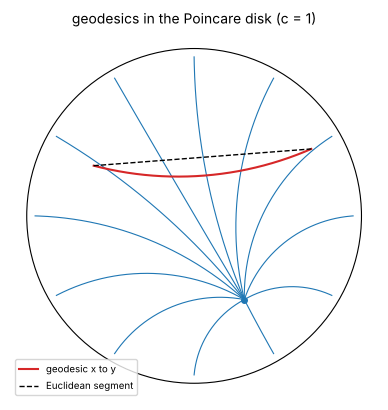

In [4]:
def geodesic(x, y, t, c=1.0):
    return mobius_add(x, scalar_mul(t, mobius_add(-x, y, c), c), c)

x, y = np.array([-0.6, 0.3]), np.array([0.7, 0.4])
ts = np.linspace(0, 1, 2001)[:, None]
path = geodesic(np.tile(x, (len(ts), 1)), np.tile(y, (len(ts), 1)), ts)
print(f"geodesic against exp_x(t log_x y): largest difference {np.abs(path - expmap(np.tile(x, (len(ts), 1)), ts * logmap(x, y))).max():.1e}")
print(f"d(x, gamma(t)) / d(x, y) at t = 0.25, 0.5, 0.75: {[round(float(dist(x, geodesic(x, y, t)) / dist(x, y)), 6) for t in (0.25, 0.5, 0.75)]}")
seg = x + ts * (y - x)                                         # the straight Euclidean segment
mid = (seg[1:] + seg[:-1]) / 2
L_seg = np.sum(lam(mid)[:, 0] * np.linalg.norm(np.diff(seg, axis=0), axis=1))
L_geo = np.sum(lam((path[1:] + path[:-1]) / 2)[:, 0] * np.linalg.norm(np.diff(path, axis=0), axis=1))
print(f"hyperbolic lengths: geodesic {L_geo:.6f} (d(x, y) = {dist(x, y):.6f}); straight Euclidean segment {L_seg:.6f}")

fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="k", lw=0.8))
start = np.array([0.3, -0.5])
for ang in np.linspace(0, 2 * np.pi, 13)[:-1]:
    end = 0.95 * np.array([np.cos(ang), np.sin(ang)])
    g = geodesic(np.tile(start, (200, 1)), np.tile(end, (200, 1)), np.linspace(0, 1, 200)[:, None])
    ax.plot(g[:, 0], g[:, 1], color="C0", lw=0.8)
ax.plot(path[:, 0], path[:, 1], color="C3", lw=1.5, label="geodesic x to y"); ax.plot(seg[:, 0], seg[:, 1], "k--", lw=1, label="Euclidean segment")
ax.plot(*start, "o", color="C0", ms=4); ax.set_aspect("equal"); ax.axis("off"); ax.legend(fontsize=7, loc="lower left")
ax.set_title("geodesics in the Poincare disk (c = 1)", fontsize=10); plt.tight_layout(); plt.show()

### 5. The Lorentz (hyperboloid) model, and converting between models
The **Lorentz model** puts the same space on the upper sheet of a hyperboloid in $\mathbb{R}^{n+1}$, using the **Minkowski inner product** $\langle x, y\rangle_L = -x_0y_0 + \sum_{i\ge1} x_iy_i$. For curvature $-c$ the points satisfy $\langle x, x\rangle_L = -1/c$ with $x_0 > 0$, and
$$d_c(x, y) = \tfrac{1}{\sqrt c}\operatorname{arcosh}\big(-c\,\langle x, y\rangle_L\big), \qquad \exp_x(v) = \cosh(\sqrt c\|v\|_L)\,x + \sinh(\sqrt c\|v\|_L)\,\frac{v}{\sqrt c\,\|v\|_L},$$
with $\|v\|_L = \sqrt{\langle v, v\rangle_L}$ for tangent vectors ($\langle x, v\rangle_L = 0$), and $\log_x(y) = d_c(x, y)\,u/\|u\|_L$ with $u = y + c\langle x, y\rangle_L\,x$. For $c = 1$ these are the formulas of Nickel & Kiela 2018. The maps between the models are
$$x = \frac{1}{\sqrt c}\cdot\frac{\big(1 + c\|p\|^2,\ 2\sqrt c\,p\big)}{1 - c\|p\|^2}, \qquad p = \frac{(x_1, \dots, x_n)}{1 + \sqrt c\,x_0}.$$
By hand, with $c = 1$: the ball point $p = (0.5, 0)$ goes to $x = (1.25, 1, 0)/0.75 = (5/3, 4/3, 0)$. Check $\langle x, x\rangle_L = -25/9 + 16/9 = -1$, and that its distance from the hyperboloid's lowest point $(1, 0, 0)$ is $\operatorname{arcosh}(5/3) = \ln 3$, as in the ball.

In [5]:
def to_lorentz(p, c=1.0):
    s = np.sum(p * p, axis=-1, keepdims=True)
    return np.concatenate([1 + c * s, 2 * np.sqrt(c) * p], axis=-1) / (np.sqrt(c) * (1 - c * s))

def to_poincare(x, c=1.0):
    return x[..., 1:] / (1 + np.sqrt(c) * x[..., :1])

def minkowski(a, b):
    return -a[..., 0] * b[..., 0] + np.sum(a[..., 1:] * b[..., 1:], axis=-1)

def lorentz_dist(a, b, c=1.0):
    return np.arccosh(np.maximum(-c * minkowski(a, b), 1.0)) / np.sqrt(c)

def lorentz_exp(x, v, c=1.0):
    nv = np.sqrt(np.maximum(minkowski(v, v), 1e-30))[..., None]
    return np.cosh(np.sqrt(c) * nv) * x + np.sinh(np.sqrt(c) * nv) * v / (np.sqrt(c) * nv)

def lorentz_log(x, y, c=1.0):
    u = y + c * minkowski(x, y)[..., None] * x
    return lorentz_dist(x, y, c)[..., None] * u / np.sqrt(np.maximum(minkowski(u, u), 1e-30))[..., None]

xh = to_lorentz(np.array([0.5, 0.0]))
print(f"by hand: (0.5, 0) -> {xh.round(6)}; <x, x>_L = {minkowski(xh, xh):.12f}; distance from (1, 0, 0): {lorentz_dist(np.array([1.0, 0, 0]), xh):.10f}")
for c in [0.5, 1.0, 2.0]:
    P_, Q_ = random_ball(500, c), random_ball(500, c)
    XL, YL = to_lorentz(P_, c), to_lorentz(Q_, c)
    Vl = lorentz_log(XL, YL, c)
    mid_L = to_poincare(lorentz_exp(XL, 0.5 * Vl, c), c)                 # geodesic midpoint computed in the Lorentz model
    print(f"c = {c}: <x,x>_L + 1/c = {np.abs(minkowski(XL, XL) + 1 / c).max():.1e}; round trip {np.abs(to_poincare(XL, c) - P_).max():.1e}; "
          f"distances agree to {np.abs(lorentz_dist(XL, YL, c) - dist(P_, Q_, c)).max():.1e}; exp(log) {np.abs(lorentz_exp(XL, Vl, c) - YL).max():.1e}; "
          f"midpoints agree to {np.abs(mid_L - geodesic(P_, Q_, 0.5, c)).max():.1e}")

by hand: (0.5, 0) -> [1.666667 1.333333 0.      ]; <x, x>_L = -1.000000000000; distance from (1, 0, 0): 1.0986122887


c = 0.5: <x,x>_L + 1/c = 8.5e-14; round trip 2.2e-16; distances agree to 1.8e-14; exp(log) 7.2e-12; midpoints agree to 2.1e-13
c = 1.0: <x,x>_L + 1/c = 2.8e-14; round trip 2.2e-16; distances agree to 1.3e-14; exp(log) 6.2e-12; midpoints agree to 1.4e-13
c = 2.0: <x,x>_L + 1/c = 1.4e-14; round trip 2.2e-16; distances agree to 6.2e-15; exp(log) 3.5e-12; midpoints agree to 7.6e-14


### 6. Numerical stability I: near the boundary, and near zero distance
Three problems, measured in float32 and float64:

* **Near the boundary.** For $\|x\| = 1 - 10^{-k}$ ($c = 1$) the exact distance from the origin is $\ln\frac{2 - 10^{-k}}{10^{-k}}$. In float32, $1 - 10^{-8}$ rounds to exactly 1 and the distance becomes infinite. Libraries therefore **clip** points to a radius: geoopt (version 0.5.1, from its source code) keeps $\|x\| \le (1 - \varepsilon)/\sqrt c$ with $\varepsilon = 4\times10^{-3}$ in float32 and $10^{-5}$ in float64; we compute the largest distance from the origin that this allows.
* **Near zero distance.** $\operatorname{arcosh}(1 + z)$ for tiny $z$: in float32, $1 + z$ rounds to 1 when $z < 6\times10^{-8}$, so distances below about $3\times10^{-4}$ come out as 0. The artanh form, and the rewriting $\operatorname{arcosh}(1 + z) = \operatorname{log1p}\big(z + \sqrt{z(z + 2)}\big)$, avoid this.
* **Gradients at coincident points.** The derivative of $\operatorname{arcosh}$ at 1 is infinite, so backpropagating through the arcosh formula at $x = y$ gives NaN in PyTorch. Clamping the argument to $\ge 1 + 10^{-7}$ avoids the NaN but makes every distance at least $\operatorname{arcosh}(1 + 10^{-7}) \approx 4.5\times10^{-4}$.

In [6]:
print("k | |x| = 1 - 10^-k | exact distance | float32 | float64")
rows6 = []
for k in range(1, 18):
    exact = np.log(2 - 10.0 ** -k) + k * np.log(10)
    with np.errstate(divide="ignore"):
        d32 = float(2 * np.arctanh(np.float32(1 - 10.0 ** -k))); d64 = float(2 * np.arctanh(1 - 10.0 ** -k))
    rows6.append((k, exact, d32, d64))
    if k in (1, 3, 5, 6, 7, 8, 15, 16, 17):
        print(f"{k:2d} | 1 - 1e-{k:<2d}       | {exact:14.6f} | {d32:9.4f} | {d64:9.4f}")
for name, eps in [("float32", 4e-3), ("float64", 1e-5)]:
    print(f"geoopt clipping in {name}: |x| <= 1 - {eps:g}, so the largest distance from the origin is {np.log((2 - eps) / eps):.2f}")

def d_arcosh32(x, y):
    one, two = np.float32(1), np.float32(2)
    return np.arccosh(one + two * np.sum((x - y) ** 2) / ((one - np.sum(x * x)) * (one - np.sum(y * y))))
def d_log1p32(x, y):
    one, two = np.float32(1), np.float32(2)
    z = two * np.sum((x - y) ** 2) / ((one - np.sum(x * x)) * (one - np.sum(y * y)))
    return np.log1p(z + np.sqrt(z * (z + two)))
def d_artanh32(x, y):
    return 2 * np.arctanh(np.linalg.norm(mobius_add(-x, y)))

x0, e0 = np.array([0.3, 0.2]), np.array([1.0, 1.0]) / np.sqrt(2)
print("points delta apart near (0.3, 0.2): delta | exact (float64) | float32: arcosh, artanh, log1p")
small = []
for k in range(1, 8):
    y0 = x0 + 10.0 ** -k * e0
    x32, y32 = x0.astype(np.float32), y0.astype(np.float32)
    vals = [float(d_arcosh32(x32, y32)), float(d_artanh32(x32, y32)), float(d_log1p32(x32, y32))]
    small.append((10.0 ** -k, float(dist(x0, y0)), vals))
    print(f"1e-{k} | {dist(x0, y0):.6e} | " + ", ".join(f"{v:.6e}" for v in vals))

xt = torch.tensor([0.3, 0.2], dtype=torch.float64, requires_grad=True)
def torch_arcosh(a, b, clamp=None):
    z = 1 + 2 * ((a - b) ** 2).sum() / ((1 - (a * a).sum()) * (1 - (b * b).sum()))
    return torch.acosh(z if clamp is None else torch.clamp(z, min=1 + clamp))
def torch_artanh(a, b):
    ab, a2, b2 = (-a * b).sum(), (a * a).sum(), (b * b).sum()
    w = ((1 + 2 * ab + b2) * (-a) + (1 - a2) * b) / (1 + 2 * ab + a2 * b2)
    return 2 * torch.atanh(torch.linalg.vector_norm(w))
for label, yv in [("same point", [0.3, 0.2]), ("1e-9 apart", [0.3 + 1e-9, 0.2])]:
    yt = torch.tensor(yv, dtype=torch.float64)
    for name, fn in [("arcosh", lambda a, b: torch_arcosh(a, b)), ("arcosh, clamped", lambda a, b: torch_arcosh(a, b, 1e-7)), ("artanh", torch_artanh)]:
        xt.grad = None; d_ = fn(xt, yt); d_.backward()
        print(f"torch, {label:10s}, {name:15s}: distance {d_.item():.3e}, gradient {xt.grad.numpy().round(4)}")

k | |x| = 1 - 10^-k | exact distance | float32 | float64
 1 | 1 - 1e-1        |       2.944439 |    2.9444 |    2.9444
 3 | 1 - 1e-3        |       7.600402 |    7.6004 |    7.6004
 5 | 1 - 1e-5        |      12.206068 |   12.2047 |   12.2061
 6 | 1 - 1e-6        |      14.508657 |   14.4955 |   14.5087
 7 | 1 - 1e-7        |      16.811243 |   16.6355 |   16.8112
 8 | 1 - 1e-8        |      19.113828 |       inf |   19.1138
15 | 1 - 1e-15       |      35.231924 |       inf |   35.2327
16 | 1 - 1e-16       |      37.534509 |       inf |   37.4299
17 | 1 - 1e-17       |      39.837094 |       inf |       inf
geoopt clipping in float32: |x| <= 1 - 0.004, so the largest distance from the origin is 6.21
geoopt clipping in float64: |x| <= 1 - 1e-05, so the largest distance from the origin is 12.21
points delta apart near (0.3, 0.2): delta | exact (float64) | float32: arcosh, artanh, log1p
1e-1 | 2.407708e-01 | 2.407707e-01, 2.407708e-01, 2.407707e-01
1e-2 | 2.308333e-02 | 2.308337e-02, 2.30

### 7. Numerical stability II: Poincaré against Lorentz far from the origin
Two points 0.1 apart on the same geodesic ray, at distance $D$ from the origin. In the ball they sit at radii $\tanh(D/2)$ and $\tanh((D + 0.1)/2)$; on the hyperboloid at $(\cosh D, \sinh D, 0)$ and $(\cosh(D + 0.1), \sinh(D + 0.1), 0)$. Both models represent the same two points; we compute their distance in float32 and float64 with three Poincaré formulas and the Lorentz formula, and report the relative error. The Lorentz inner product $-x_0y_0 + x_1y_1$ subtracts two numbers of size about $e^{2D}/4$ to get $\cosh 0.1 \approx 1.005$; the artanh form subtracts numbers of size 1 in the numerator of Möbius addition.

float32: largest D with relative error below 1%: Poincare, artanh 6, Poincare, arcosh 10, Poincare, log1p 10, Lorentz 4
float64: largest D with relative error below 1%: Poincare, artanh 16, Poincare, arcosh 30, Poincare, log1p 30, Lorentz 14


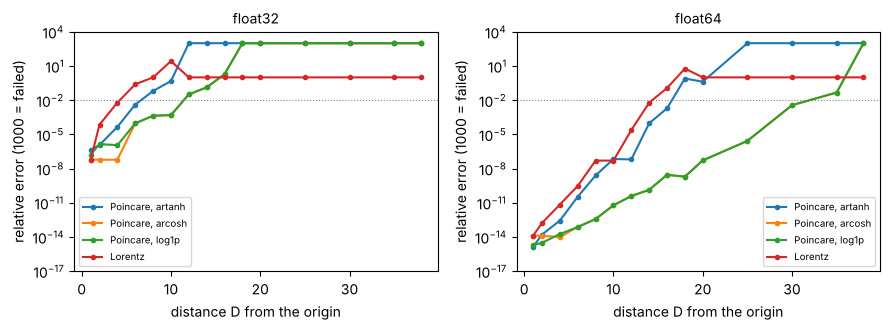

runtime so far 0.7 s


In [7]:
def poincare_three(p, q):
    one, two = p.dtype.type(1), p.dtype.type(2)
    z = two * np.sum((p - q) ** 2) / ((one - np.sum(p * p)) * (one - np.sum(q * q)))
    return [2 * np.arctanh(np.linalg.norm(mobius_add(-p, q))), np.arccosh(one + z), np.log1p(z + np.sqrt(z * (z + two)))]

Ds = [1, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 25, 30, 35, 38]
labels = ["Poincare, artanh", "Poincare, arcosh", "Poincare, log1p", "Lorentz"]
errs = {dt.__name__: {l: [] for l in labels} for dt in (np.float32, np.float64)}
for D in Ds:
    p = np.array([np.tanh(D / 2), 0.0]); q = np.array([np.tanh((D + 0.1) / 2), 0.0])
    xl = np.array([np.cosh(D), np.sinh(D), 0.0]); yl = np.array([np.cosh(D + 0.1), np.sinh(D + 0.1), 0.0])
    for dt in (np.float32, np.float64):
        with np.errstate(all="ignore"):
            vals = [float(v) for v in poincare_three(p.astype(dt), q.astype(dt))]
            xx, yy = xl.astype(dt), yl.astype(dt)
            m_ = -(xx[0] * yy[0]) + xx[1] * yy[1]
            vals.append(float(np.arccosh(-m_)) if -m_ >= 1 else 0.0)        # rounding can push -<x,y> below 1
        for l, v in zip(labels, vals):
            errs[dt.__name__][l].append(abs(v - 0.1) / 0.1 if np.isfinite(v) else np.inf)
for dname in errs:
    print(f"{dname}: largest D with relative error below 1%: " +
          ", ".join(f"{l} {max([D for D, e in zip(Ds, errs[dname][l]) if e < 0.01], default='none')}" for l in labels))

fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
for a_, dname in zip(ax, errs):
    for l in labels:
        e = np.array(errs[dname][l]); e = np.where(np.isfinite(e), np.maximum(e, 1e-17), 1e3)
        a_.semilogy(Ds, e, "o-", ms=3, label=l)
    a_.axhline(0.01, color="0.5", lw=0.8, ls=":"); a_.set_ylim(1e-17, 1e4)
    a_.set_xlabel("distance D from the origin"); a_.set_ylabel("relative error (1000 = failed)"); a_.set_title(dname, fontsize=10); a_.legend(fontsize=7)
plt.tight_layout(); plt.show()
print(f"runtime so far {time.time() - t_start:.1f} s")

### 8. The same with geoopt
geoopt's `PoincareBall(c)` uses curvature $-c$ and the formulas above; its `Lorentz(k)` stores points with $\langle x, x\rangle_L = -k$, so for $k = 1$ it matches our $c = 1$. geoopt is not installed here, so this cell is NOT RUN (in Colab or Kaggle, run `pip install geoopt` first).

In [ ]:
# NOT RUN: needs geoopt (pip install geoopt), which is not installed here
import torch
import geoopt

ball = geoopt.PoincareBall(c=1.0)                                     # curvature -1
x = torch.tensor([0.5, 0.0], dtype=torch.float64); y = torch.tensor([0.0, 0.5], dtype=torch.float64)
print(ball.mobius_add(x, y), ball.mobius_add(y, x))                    # (0.5882, 0.3529) and (0.3529, 0.5882)
print(ball.dist(torch.zeros(2, dtype=torch.float64), x))               # ln 3 = 1.0986
v = ball.logmap(x, y)
print(ball.expmap(x, v), ball.norm(x, v), ball.dist(x, y))             # y again; the Riemannian norm of log_x(y) is d(x, y)

hyperboloid = geoopt.Lorentz(k=1.0)                                    # points with <x, x>_L = -1
def to_lorentz(p):
    s = (p * p).sum(-1, keepdim=True)
    return torch.cat([1 + s, 2 * p], dim=-1) / (1 - s)
print(hyperboloid.dist(to_lorentz(x), to_lorentz(y)), ball.dist(x, y))   # the same distance in both models

### 9. Exercises

In [8]:
# TODO: exp and log at any point from exp and log at the origin. Check numerically, for c = 1 and c = 2 on 200 random
# pairs, that exp_x(v) = x (+) exp_0(lambda_x v / 2) and log_x(y) = (2 / lambda_x) log_0((-x) (+) y), using expmap,
# logmap, mobius_add and lam from above (exp_0 and log_0 are expmap and logmap with x = 0). Return the two largest errors.
# Why do these identities hold? (Hint: left translation by x is an isometry that sends 0 to x.)
def exp_log_via_origin():
    return None          # replace with your code

r = exp_log_via_origin()
print("not done yet" if r is None else r)

not done yet


In [9]:
# TODO: how far out can the Lorentz model go in float32? For D = 1, 2, ..., 12, store x = (cosh D, sinh D, 0) in float32 and
# compute <x, x>_L in float32. Return the largest D for which |<x, x>_L + 1| < 0.01. Compare with the D at which the Lorentz
# distance in section 7 failed, and explain both with the size of cosh(D)^2 and the float32 machine epsilon (about 6e-8).
def lorentz_float32_limit():
    return None          # replace with your code

r = lorentz_float32_limit()
print("not done yet" if r is None else f"largest D: {r}")

not done yet


### What to notice
(Written from the run above; your numbers will match if you keep the seeds.)

1. **Möbius addition is not vector addition.** In one dimension $0.5 \oplus 0.5 = 0.8$, not 1, and the result stays inside the ball. In two dimensions $(0.5, 0)\oplus(0, 0.5) = (0.5882, 0.3529)$ but $(0, 0.5)\oplus(0.5, 0) = (0.3529, 0.5882)$: the same norm, 0.6860, in a different direction.
2. **The formulas hold for every curvature.** For $c$ = 0.5, 1 and 2, the artanh and arcosh distances agreed to about 1e-14, exp and log inverted each other, and $\lambda_x\|\log_x y\| = d(x, y)$. $d_1(0, (0.5, 0)) = \ln 3$ and $d_2(0, (0.5, 0)) = 1.2465$, as computed by hand. As $c$ fell from 1e-2 to 1e-6, $d_c(x, y)$ approached $2\|x - y\|$ (gap 6.5e-03 to 6.5e-07): small curvature is nearly flat.
3. **What survives of the vector-space rules.** Left cancellation held to 1.1e-14 and left translations kept distances to 2.3e-14. Commutativity failed (differences up to 1.033, though the norms agreed to 3.3e-16), associativity failed (up to 0.900) but the gyroassociative law held to 3.8e-15, and right translations changed distances by up to 0.22. In one dimension, Möbius addition commuted.
4. **Geodesics are arcs.** The geodesic formula matched $\exp_x(t\log_x y)$ to 3.7e-15 and divided the distance in proportion to $t$. The straight Euclidean segment between the same two points had hyperbolic length 3.728216, longer than the geodesic's 3.618936.
5. **The Lorentz model is the same space.** $(0.5, 0)$ went to $(5/3, 4/3, 0)$ with $\langle x, x\rangle_L = -1$ and distance $\ln 3$ from the bottom of the hyperboloid. For all three curvatures, distances agreed with the ball to about 1e-14 and geodesic midpoints computed in the two models agreed to about 1e-13.
6. **Every formula has a weak spot.** Near the boundary, float32 gave 16.6355 instead of 16.811243 at $\|x\| = 1 - 10^{-7}$ and infinity from $1 - 10^{-8}$ on; float64 failed only at $1 - 10^{-17}$. geoopt's default clipping limits points to distance 6.21 (float32) or 12.21 (float64) from the origin. For tiny distances, the arcosh formula in float32 returned 0 from $\delta = 10^{-4}$ on, while the artanh and log1p forms stayed close. In PyTorch, the arcosh formula gave NaN gradients at coincident points; clamping removed the NaN but reported a distance of 4.472e-04 for identical points, while the artanh form gave distance 0 and gradient 0, and the correct gradient 1e-9 apart.
7. **Far from the origin the Poincaré ball beat the Lorentz model.** For two points 0.1 apart, the relative error stayed below 1% up to distance 30 in float64 with the arcosh or log1p Poincaré formula, but only up to 14 with the Lorentz formula; in float32, up to 10 against 4. (A relative error of exactly 1 in the plot means the computed distance was 0, because rounding made the Lorentz argument less than 1.) The artanh form, the best one near zero distance, was the worst Poincaré formula far out (16 in float64, 6 in float32), because its Möbius numerator subtracts numbers of size 1. No single formula is best everywhere.
